In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    make_scorer
)

In [2]:
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

dataset_path = (
    project_root
    / "data"
    / "raw"
    / "manufacturing_6G_dataset.csv"
)

figures_dir = project_root / "figures"
figures_dir.mkdir(exist_ok=True)

df = pd.read_csv(dataset_path)

df["Timestamp"] = pd.to_datetime(
    df["Timestamp"]
)

print("Dataset shape:", df.shape)

Dataset shape: (100000, 13)


In [3]:
X = df.drop(
    columns=[
        "Efficiency_Status",
        "Timestamp",
        "Machine_ID"
    ]
)

y = df["Efficiency_Status"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100000, 10)
y shape: (100000,)


In [4]:
X_development, X_test, y_development, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

X_train, X_validation, y_train, y_validation = (
    train_test_split(
        X_development,
        y_development,
        test_size=0.20,
        random_state=42,
        stratify=y_development
    )
)

print("Training:", X_train.shape)
print("Validation:", X_validation.shape)
print("Final Test:", X_test.shape)

Training: (64000, 10)
Validation: (16000, 10)
Final Test: (20000, 10)


In [5]:
numerical_features = [
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW",
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Quality_Control_Defect_Rate_%",
    "Production_Speed_units_per_hr",
    "Predictive_Maintenance_Score",
    "Error_Rate_%"
]

categorical_features = [
    "Operation_Mode"
]

class_order = [
    "Low",
    "Medium",
    "High"
]

In [6]:
sgd_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [7]:
tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            "passthrough",
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [8]:
# recreating the notebook 3 models
dummy_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            tree_preprocessor
        ),
        (
            "model",
            DummyClassifier(
                strategy="most_frequent"
            )
        )
    ]
)

In [9]:
#SGD
sgd_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            sgd_preprocessor
        ),
        (
            "model",
            SGDClassifier(
                random_state=42,
                max_iter=2000
            )
        )
    ]
)

In [10]:
tree_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            tree_preprocessor
        ),
        (
            "model",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)

In [11]:
#pipeline for Random Forest
forest_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            tree_preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

forest_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, de

In [12]:
forest_pipeline.fit(
    X_train,
    y_train
)

print(
    "Random Forest trained successfully."
)

Random Forest trained successfully.


In [13]:
forest_predictions = (
    forest_pipeline.predict(
        X_validation
    )
)

print(
    forest_predictions[:10]
)

['Low' 'Low' 'Medium' 'Medium' 'Low' 'Low' 'Low' 'Low' 'Medium' 'Low']


In [14]:
forest_accuracy = accuracy_score(
    y_validation,
    forest_predictions
)

forest_macro_precision = precision_score(
    y_validation,
    forest_predictions,
    average="macro",
    zero_division=0
)

forest_macro_recall = recall_score(
    y_validation,
    forest_predictions,
    average="macro",
    zero_division=0
)

forest_macro_f1 = f1_score(
    y_validation,
    forest_predictions,
    average="macro",
    zero_division=0
)

print(
    "Accuracy:",
    round(forest_accuracy, 4)
)

print(
    "Macro Precision:",
    round(forest_macro_precision, 4)
)

print(
    "Macro Recall:",
    round(forest_macro_recall, 4)
)

print(
    "Macro F1:",
    round(forest_macro_f1, 4)
)

Accuracy: 1.0
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1: 1.0


In [15]:
print(
    classification_report(
        y_validation,
        forest_predictions,
        labels=class_order,
        zero_division=0
    )
)

              precision    recall  f1-score   support

         Low       1.00      1.00      1.00     12452
      Medium       1.00      1.00      1.00      3070
        High       1.00      1.00      1.00       478

    accuracy                           1.00     16000
   macro avg       1.00      1.00      1.00     16000
weighted avg       1.00      1.00      1.00     16000



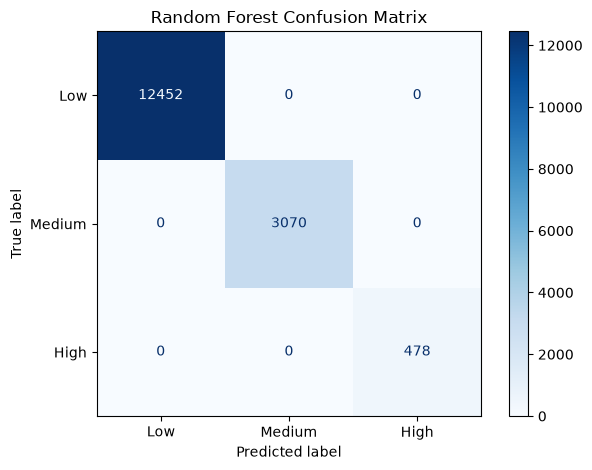

In [16]:
ConfusionMatrixDisplay.from_predictions(
    y_validation,
    forest_predictions,
    labels=class_order,
    cmap="Blues"
)

plt.title(
    "Random Forest Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    figures_dir
    / "random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Cross Validation

In [17]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv

StratifiedKFold(n_splits=3, random_state=42, shuffle=True)

In [18]:
scoring = {
    "accuracy": "accuracy",

    "macro_precision": make_scorer(
        precision_score,
        average="macro",
        zero_division=0
    ),

    "macro_recall": make_scorer(
        recall_score,
        average="macro",
        zero_division=0
    ),

    "macro_f1": make_scorer(
        f1_score,
        average="macro",
        zero_division=0
    )
}

In [19]:
def run_cross_validation(
    model_name,
    model,
    X_data,
    y_data
):

    scores = cross_validate(
        model,
        X_data,
        y_data,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    result = {
        "Model": model_name,

        "Train Macro F1":
            scores[
                "train_macro_f1"
            ].mean(),

        "CV Accuracy":
            scores[
                "test_accuracy"
            ].mean(),

        "CV Macro Precision":
            scores[
                "test_macro_precision"
            ].mean(),

        "CV Macro Recall":
            scores[
                "test_macro_recall"
            ].mean(),

        "CV Macro F1":
            scores[
                "test_macro_f1"
            ].mean(),

        "CV Macro F1 Std":
            scores[
                "test_macro_f1"
            ].std()
    }

    return result

In [20]:
dummy_cv_result = run_cross_validation(
    "Majority Baseline",
    dummy_pipeline,
    X_train,
    y_train
)

dummy_cv_result

{'Model': 'Majority Baseline',
 'Train Macro F1': np.float64(0.29176624958513897),
 'CV Accuracy': np.float64(0.7782500001358622),
 'CV Macro Precision': np.float64(0.259416666711954),
 'CV Macro Recall': np.float64(0.3333333333333333),
 'CV Macro F1': np.float64(0.2917662495706958),
 'CV Macro F1 Std': np.float64(4.237645948271228e-06)}

In [21]:
sgd_cv_result = run_cross_validation(
    "SGD Classifier",
    sgd_pipeline,
    X_train,
    y_train
)

sgd_cv_result

{'Model': 'SGD Classifier',
 'Train Macro F1': np.float64(0.7939282276317742),
 'CV Accuracy': np.float64(0.9077031278845755),
 'CV Macro Precision': np.float64(0.9023056050388402),
 'CV Macro Recall': np.float64(0.7384882431241101),
 'CV Macro F1': np.float64(0.7954311441806027),
 'CV Macro F1 Std': np.float64(0.0044296550794819855)}

In [22]:
tree_cv_result = run_cross_validation(
    "Decision Tree",
    tree_pipeline,
    X_train,
    y_train
)

tree_cv_result

{'Model': 'Decision Tree',
 'Train Macro F1': np.float64(1.0),
 'CV Accuracy': np.float64(0.9999374997558327),
 'CV Macro Precision': np.float64(0.9999527935735731),
 'CV Macro Recall': np.float64(0.9997441313974768),
 'CV Macro F1': np.float64(0.9998483764827778),
 'CV Macro F1 Std': np.float64(0.000123517988464347)}

In [23]:
forest_cv_result = run_cross_validation(
    "Random Forest",
    forest_pipeline,
    X_train,
    y_train
)

forest_cv_result

{'Model': 'Random Forest',
 'Train Macro F1': np.float64(1.0),
 'CV Accuracy': np.float64(0.9999375012206535),
 'CV Macro Precision': np.float64(0.9999119478270924),
 'CV Macro Recall': np.float64(0.9994495671435395),
 'CV Macro F1': np.float64(0.9996801232585616),
 'CV Macro F1 Std': np.float64(0.0004169944902206847)}

In [24]:
cv_results = pd.DataFrame([
    dummy_cv_result,
    sgd_cv_result,
    tree_cv_result,
    forest_cv_result
])

cv_results.round(4)

,Model,Train Macro F1,CV Accuracy,CV Macro Precision,CV Macro Recall,CV Macro F1,CV Macro F1 Std
0,Majority Baseline,0.2918,0.7783,0.2594,0.3333,0.2918,0.0000
1,SGD Classifier,0.7939,0.9077,0.9023,0.7385,0.7954,0.0044
2,Decision Tree,1.0000,0.9999,1.0000,0.9997,0.9998,0.0001
3,Random Forest,1.0000,0.9999,0.9999,0.9994,0.9997,0.0004


In [25]:
cv_results.sort_values(
    by="CV Macro F1",
    ascending=False
)

,Model,Train Macro F1,CV Accuracy,CV Macro Precision,CV Macro Recall,CV Macro F1,CV Macro F1 Std
2,Decision Tree,1.000000,0.999937,0.999953,0.999744,0.999848,0.000124
3,Random Forest,1.000000,0.999938,0.999912,0.999450,0.999680,0.000417
1,SGD Classifier,0.793928,0.907703,0.902306,0.738488,0.795431,0.004430
0,Majority Baseline,0.291766,0.778250,0.259417,0.333333,0.291766,0.000004


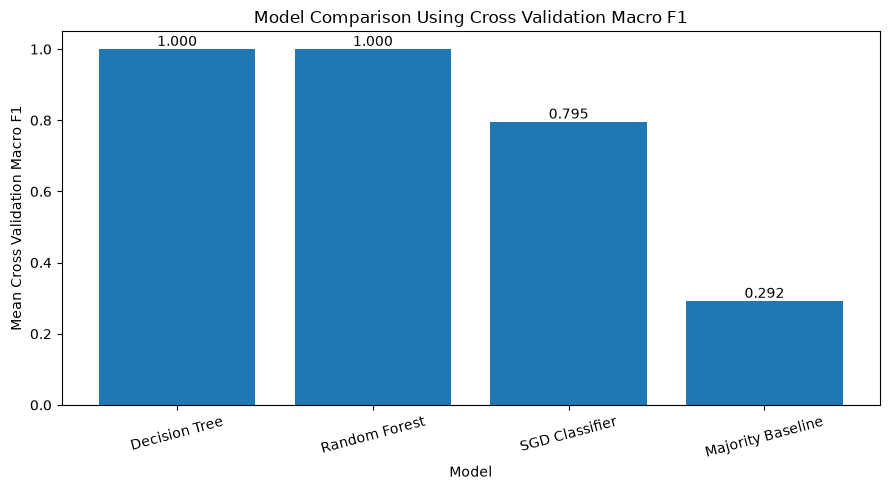

In [26]:
sorted_results = (
    cv_results
    .sort_values(
        "CV Macro F1",
        ascending=False
    )
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    sorted_results["Model"],
    sorted_results["CV Macro F1"]
)

plt.title(
    "Model Comparison Using Cross Validation Macro F1"
)

plt.xlabel(
    "Model"
)

plt.ylabel(
    "Mean Cross Validation Macro F1"
)

plt.ylim(
    0,
    1.05
)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        height,
        f"{height:.3f}",
        ha="center",
        va="bottom"
    )

plt.xticks(
    rotation=15
)

plt.tight_layout()

plt.savefig(
    figures_dir
    / "cross_validation_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
overfitting_check = cv_results[
    [
        "Model",
        "Train Macro F1",
        "CV Macro F1"
    ]
].copy()

overfitting_check[
    "F1 Gap"
] = (
    overfitting_check[
        "Train Macro F1"
    ]
    -
    overfitting_check[
        "CV Macro F1"
    ]
)

overfitting_check.round(4)

,Model,Train Macro F1,CV Macro F1,F1 Gap
0,Majority Baseline,0.2918,0.2918,0.0000
1,SGD Classifier,0.7939,0.7954,-0.0015
2,Decision Tree,1.0000,0.9998,0.0002
3,Random Forest,1.0000,0.9997,0.0003


In [28]:
forest_cv_predictions = (
    cross_val_predict(
        forest_pipeline,
        X_train,
        y_train,
        cv=cv,
        n_jobs=-1
    )
)

In [32]:
print(
    classification_report(
        y_train,
        forest_cv_predictions,
        labels=class_order,
        zero_division=0,
        digits=4
    )
)

              precision    recall  f1-score   support

         Low     1.0000    1.0000    1.0000     49808
      Medium     0.9998    0.9999    0.9998     12281
        High     1.0000    0.9984    0.9992      1911

    accuracy                         0.9999     64000
   macro avg     0.9999    0.9994    0.9997     64000
weighted avg     0.9999    0.9999    0.9999     64000



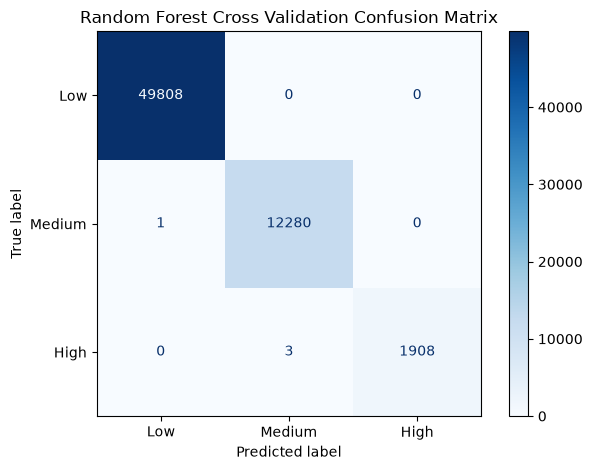

In [34]:
ConfusionMatrixDisplay.from_predictions(
    y_train,
    forest_cv_predictions,
    labels=class_order,
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Random Forest Cross Validation Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [31]:
print(
    "Final test set size:",
    len(X_test)
)

print(
    "The final test set has not been "
    "used for model selection."
)

Final test set size: 20000
The final test set has not been used for model selection.


# Random Forest and Cross Validation Conclusions

## Random Forest Classifier

A Random Forest Classifier was introduced as an ensemble based extension of the Decision Tree model.

Instead of relying on a single Decision Tree, Random Forest trains multiple trees using different samples and feature subsets.

The final classification is obtained by combining the predictions from the individual trees.

The model was configured with:

`100 Decision Trees`

`random_state = 42`

Random Forest does not require numerical feature standardization because its individual trees make threshold based decisions.

## Cross Validation

Three fold stratified cross validation was used to obtain a more reliable estimate of model performance.

The training dataset was divided into three folds.

Each fold was used as validation data once while the remaining two folds were used for training.

This produced three independent validation results for each model.

Stratification was used to preserve the approximate proportions of:

`Low`

`Medium`

`High`

efficiency observations within each fold.

## Models Compared

The following models were evaluated using the same cross validation strategy:

`Majority Baseline`

`SGD Classifier`

`Decision Tree Classifier`

`Random Forest Classifier`

## Evaluation Metrics

The models were compared using:

`Accuracy`

`Macro Precision`

`Macro Recall`

`Macro F1`

Macro averaged metrics were emphasized because the target classes are strongly imbalanced.

Macro F1 gives equal importance to Low, Medium, and High efficiency classes regardless of how many observations belong to each class.

## Model Stability

The mean cross validation score represents the typical performance of the model across the different validation folds.

The standard deviation of the cross validation Macro F1 score was also calculated.

A small standard deviation indicates that model performance is relatively consistent across different subsets of the data.

A larger standard deviation indicates that model performance is more dependent on the specific training and validation split.

## Overfitting Analysis

Training Macro F1 was compared with cross validation Macro F1.

A large difference between training and cross validation performance can indicate overfitting.

A small difference suggests that the model generalizes more consistently to observations that were not used during training.

## Random Forest Interpretation

Random Forest is expected to perform strongly on this dataset because the previous exploratory analysis identified clear threshold based relationships involving:

`Production_Speed_units_per_hr`

`Error_Rate_%`

These variables can reproduce the provided `Efficiency_Status` labels using simple threshold conditions.

Therefore, extremely high performance from Decision Tree or Random Forest models should be interpreted together with the known structure of the target variable.

High predictive performance does not automatically demonstrate that the model has learned complex relationships across all manufacturing sensor variables.

## Final Test Set

The final test dataset remained untouched during notebook 4.

It will only be used after model development and model selection have been completed.

## Cross Validation Results

The Majority Baseline achieved approximately 77.83% accuracy but only 0.292 Macro F1, demonstrating that high accuracy can be misleading because the Low efficiency class dominates the dataset.

The SGD Classifier substantially improved performance, achieving approximately 90.77% cross validation accuracy and 0.795 Macro F1.

The Decision Tree achieved approximately 99.994% cross validation accuracy and 0.99985 Macro F1.

The Random Forest achieved approximately 99.994% cross validation accuracy and 0.99968 Macro F1.

The Decision Tree therefore achieved the highest Macro F1 score, although the performance difference between Decision Tree and Random Forest was extremely small.

Both tree based models also showed very small variation across the three cross validation folds.

The Random Forest cross validated predictions contained only four classification errors among 64,000 observations. One Medium observation was classified as Low, while three High observations were classified as Medium.

These extremely high results are consistent with the threshold based structure identified during the exploratory analysis. Therefore, the results should not be interpreted as evidence that the models learned complex relationships across all manufacturing variables.

## Conclusion

Cross validation provides stronger evidence about model performance than a single validation split.

Random Forest provides an ensemble based alternative to a single Decision Tree and allows the stability of threshold based classification to be evaluated.

The next stage will investigate why the strongest models perform well.

Notebook 5 will focus on:

`Feature Importance`

`Production Speed and Error Rate`

`Feature Ablation`

`Model Performance Without the Dominant Features`

This will help determine whether the high classification performance depends primarily on the two variables identified during the exploratory analysis.